In [91]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"X:\data\Barrage\NN16\day13"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
try:
    # Try default loader
    epoch_df = loading.load_epoch(basepath)
except Exception as e:
    print(f"load_epoch failed with error: {e}")
    print("Falling back to manual .mat file load...")

    # Load the .mat file
    mat = sio.loadmat(os.path.join(basepath, "DayNight25.MergePoints.events.mat"), squeeze_me=True)

    # Extract the 'MergePoints' structure
    merge_points = mat['MergePoints']

    # Extract the timestamps array: shape (N, 2)
    timestamps = merge_points['timestamps']
    # Unwrap the array inside
    timestamps = np.array(timestamps.tolist())

    epoch_df = pd.DataFrame(timestamps, columns=["startTime", "stopTime"])

sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
spike_times=st.time
n_cell=len(spike_times)
print(f"number of cells: {n_cell}")

Folder already exists: X:\data\Barrage\NN16\day13\complex_system
number of cells: 60


In [92]:
epoch_df

,name,startTime,stopTime,environment,manipulation,behavioralParadigm,stimuli,notes,basepath
0,presleep_230419_092616,0.0000,9292.70395,sleep,NaN,NaN,NaN,NaN,X:\data\Barrage\NN16\day13
1,tmaze_230419_120338,9292.7040,12457.00000,tmaze,NaN,NaN,NaN,NaN,X:\data\Barrage\NN16\day13
2,postsleep_230419_130431,12456.7424,22260.34555,sleep,NaN,NaN,NaN,NaN,X:\data\Barrage\NN16\day13


In [93]:
import os, re, numpy as np, pandas as pd
import glob
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Coerce a MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Complete version that loads ALL sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    # pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    pats = [f"*_{region}_D2_time_resolved_barrageablate.mat", f"*_{region}_D2_time_barrageablate.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



# Load the CA1 d2 timeline
try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

Loading: day13_CA1_D2_time_resolved_barrageablate.mat
📊 Found 3 result items (sleep states)
📊 Parameters: {'window_size': 30, 'step_size': 2, 'guard_sec': 5, 'deltaT': 0.04, 'order': 20, 'quant': 0.1, 'brain_region': 'CA1', 'n_cells': 61, 'total_spikes': 2573481}
   State 0: NREM - requested points=2163, actual used=2163
     Time range: 1492.0 to 22212.0
     D2 range: 0.0408 to 0.2527
     D2_ERR range: 0.8855 to 0.9758
   State 1: REM - requested points=0, actual used=0
     ⚠️ Empty state - no data points
   State 2: WAKE - requested points=3508, actual used=3508
     Time range: 21.0 to 22116.0
     D2 range: 0.0233 to 0.2132
     D2_ERR range: 0.7318 to 0.9662

✅ Complete timeline created:
📊 Total data points: 5671
📊 Time range: 21.0 to 22212.0
📊 Duration: 22191.0 seconds
📊 State distribution:
state
WAKE    3508
NREM    2163
Name: count, dtype: int64



In [94]:
ca1_complete_df

,center_s,d2,d2_err,state
0,21.0,0.086790,0.763020,WAKE
1,23.0,0.089156,0.758124,WAKE
2,25.0,0.100650,0.746467,WAKE
3,27.0,0.102190,0.761508,WAKE
4,29.0,0.104524,0.760505,WAKE
...,...,...,...,...
5666,22204.0,0.090452,0.942271,NREM
5667,22206.0,0.078833,0.945290,NREM
5668,22208.0,0.085976,0.941829,NREM
5669,22210.0,0.079233,0.943683,NREM


In [95]:
import numpy as np
import scipy.io as sio      
import scipy
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
    # Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps= barrage.timestamps 
    barrage_epochs=nrem_epochs&barrage_epochs
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
    # Extract start times

In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Iterable

# =========================
# ISI entropy
# =========================
def isi_entropy(spike_times, n_bins=20):
    """
    Shannon entropy (bits) of log10(ISI) distribution.
    Returns NaN if fewer than 2 ISIs (i.e., <3 spikes).
    """
    st = np.asarray(spike_times, float)
    st = st[np.isfinite(st)]
    st = np.unique(np.sort(st))
    if st.size < 3:
        return np.nan
    isis = np.diff(st)
    isis = isis[np.isfinite(isis) & (isis > 0)]
    if isis.size < 2:
        return np.nan
    x = np.log10(isis)
    hist, _ = np.histogram(x, bins=n_bins)
    N = hist.sum()
    if N <= 0:
        return np.nan
    p = hist.astype(float) / N
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))  # bits

# =========================
# Utilities
# =========================
def _flatten_spikes(spike_times):
    """Pool spike times across inputs and return sorted unique float seconds."""
    if isinstance(spike_times, dict):
        parts = [np.asarray(v, float).ravel() for v in spike_times.values()]
        x = np.concatenate([p[np.isfinite(p)] for p in parts]) if parts else np.array([], float)
    else:
        arr = np.asarray(spike_times, dtype=object)
        if arr.dtype == object:
            parts = []
            for it in arr:
                if it is None:
                    continue
                v = np.asarray(it, float).ravel()
                v = v[np.isfinite(v)]
                if v.size:
                    parts.append(v)
            if parts:
                x = np.concatenate(parts)
            else:
                try:
                    x = np.asarray(spike_times, float).ravel()
                except (TypeError, ValueError):
                    x = np.array([], float)
        else:
            x = arr.astype(float).ravel()
    x = x[np.isfinite(x)]
    return np.sort(np.unique(x))

def _coerce_epochs(ep):
    """Coerce many epoch formats to a sorted list[(start, stop)]. Accepts ep, or ep.data with ≥2 columns."""
    # Try .data first (Epoch-like objects)
    if hasattr(ep, "data"):
        vals = getattr(ep, "data")
        try:
            if isinstance(vals, pd.DataFrame) and vals.shape[1] >= 2:
                a = vals.iloc[:, 0].astype(float).to_numpy()
                b = vals.iloc[:, 1].astype(float).to_numpy()
                out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
                out.sort(key=lambda t: t[0]); return out
            vals = np.asarray(vals)
            if vals.ndim == 2 and vals.shape[1] >= 2:
                a = vals[:, 0].astype(float); b = vals[:, 1].astype(float)
                out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
                out.sort(key=lambda t: t[0]); return out
        except Exception:
            pass

    # DataFrame
    if isinstance(ep, pd.DataFrame):
        if {'start','stop'}.issubset(ep.columns):
            a = ep['start'].astype(float).to_numpy()
            b = ep['stop'].astype(float).to_numpy()
        elif {'startTime','stopTime'}.issubset(ep.columns):
            a = ep['startTime'].astype(float).to_numpy()
            b = ep['stopTime'].astype(float).to_numpy()
        else:
            a = ep.iloc[:,0].astype(float).to_numpy()
            b = ep.iloc[:,1].astype(float).to_numpy()
        out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
        out.sort(key=lambda t: t[0]); return out

    # Iterable of pairs
    if isinstance(ep, Iterable):
        out = []
        for item in ep:
            try:
                s, e = item
                s, e = float(s), float(e)
                if np.isfinite(s) and np.isfinite(e) and e > s:
                    out.append((s, e))
            except Exception:
                pass
        out.sort(key=lambda t: t[0]); return out

    return []

def _count_events(event_epochs, a, b):
    """Count events whose mid-point falls in [a,b)."""
    c = 0
    for s, e in event_epochs:
        if not np.isfinite(s) or not np.isfinite(e) or e <= s:
            continue
        mid = 0.5 * (s + e)
        if a <= mid < b:
            c += 1
    return c

# =========================
# Core: ISI entropy per window + ripple/barrage rates
# =========================
def isi_entropy_windows_with_tiles(
    spike_times,
    centers_df,                 # must have columns: center_s, state
    ripple_epochs,
    barrage_epochs,
    state_filter="NREM",
    window=10.0,                # seconds (±15s)
    min_spikes=3,               # require ≥3 spikes in window to form ≥2 ISIs
    n_bins_isi=20               # histogram bins for log10(ISI)
):
    st = _flatten_spikes(spike_times)
    out_cols = ["center_s","state","isi_entropy","n_spikes","ripple_rate","barrage_rate"]
    if st.size == 0:
        return pd.DataFrame(columns=out_cols)

    # centers (NREM only by default)
    # centers (NREM only by default)
    if "state" in centers_df.columns:
        sel = centers_df["state"].astype(str).str.upper() == str(state_filter).upper()
        cdf = centers_df.loc[sel & centers_df["center_s"].notna()].copy()
    else:
        cdf = centers_df.loc[centers_df["center_s"].notna()].copy()
        cdf["state"] = state_filter


    rip = _coerce_epochs(ripple_epochs)
    bar = _coerce_epochs(barrage_epochs)

    half = window/2.0
    rows = []
    for i, (c, s) in enumerate(zip(
        cdf["center_s"].to_numpy(float),
        cdf["state"].astype(str).to_numpy()
    )):
        a, b = c - half, c + half
        # spikes in window
        wst = st[(st >= a) & (st < b)]
        nsp = int(wst.size)

        if nsp >= min_spikes:
            H = isi_entropy(wst, n_bins=n_bins_isi)
        else:
            H = np.nan

        dur = b - a
        if dur > 0:
            rr = _count_events(rip, a, b) / dur
            br = _count_events(bar, a, b) / dur
        else:
            rr = np.nan; br = np.nan

        # start with all original metadata from centers_df (current row index)
        row_dict = cdf.iloc[i].to_dict()

        # add new fields
        row_dict.update({
            "isi_entropy": H,
            "n_spikes": nsp,
            "ripple_rate": rr,
            "barrage_rate": br
        })

        rows.append(row_dict)

    out = pd.DataFrame(rows).sort_values("center_s").reset_index(drop=True)
    print(out.head())
    return out

# =========================
# Tile aggregation (6 tiles) and plotting
# =========================
def _make_tiles(series, k=6):
    """Return categorical Q1..Qk for the given series using quantiles; robust to ties."""
    v = pd.Series(series.to_numpy(float))
    ok = np.isfinite(v)
    if ok.sum() == 0:
        return pd.Categorical([np.nan] * len(v), categories=[f"Q{i}" for i in range(1, k+1)], ordered=True)
    try:
        # Use up to k quantiles, but not more than unique values
        q = min(k, max(1, v[ok].nunique()))
        labels = [f"Q{i}" for i in range(1, q+1)]
        lab = pd.qcut(v[ok], q=q, labels=labels, duplicates="drop")
    except ValueError:
        # Fallback to rank-based tiling
        r = v[ok].rank(method="first")
        q = min(k, max(1, r.nunique()))
        if q == 1:
            lab = pd.Categorical(['Q1']*ok.sum(), categories=['Q1'], ordered=True)
        else:
            labels = [f"Q{i}" for i in range(1, q+1)]
            lab = pd.qcut(r, q=q, labels=labels, duplicates='drop')

    # place back with full set Q1..Qk (even if some are empty)
    out_cats = [f"Q{i}" for i in range(1, k+1)]
    out = pd.Series(pd.Categorical([np.nan]*len(v), categories=out_cats, ordered=True))
    out.loc[v.index[ok]] = lab
    return out

def aggregate_tiles(df, by="ripple", value_col="isi_entropy", k=6):
    """
    Aggregate 'value_col' by k quantile tiles of 'ripple_rate' or 'barrage_rate'.
    Returns a tidy DataFrame with mean, SEM, and n per tile.
    """
    assert by in ("ripple", "barrage")
    rate_col = "ripple_rate" if by == "ripple" else "barrage_rate"
    tile_col = "tile_ripple" if by == "ripple" else "tile_barrage"

    dd = df.dropna(subset=[value_col, rate_col]).copy()
    if dd.empty:
        cats = [f"Q{i}" for i in range(1, k+1)]
        return pd.DataFrame({tile_col: pd.Categorical([], categories=cats, ordered=True),
                             f"{value_col}_mean": pd.Series([], dtype=float),
                             f"{value_col}_sem": pd.Series([], dtype=float),
                             "n": pd.Series([], dtype=int)})

    dd[tile_col] = _make_tiles(dd[rate_col], k=k)
    if dd[tile_col].isna().all():
        cats = [f"Q{i}" for i in range(1, k+1)]
        return pd.DataFrame({tile_col: pd.Categorical([], categories=cats, ordered=True),
                             f"{value_col}_mean": pd.Series([], dtype=float),
                             f"{value_col}_sem": pd.Series([], dtype=float),
                             "n": pd.Series([], dtype=int)})

    g = dd.groupby(tile_col, observed=False)
    res = g.agg(**{
        f"{value_col}_mean": (value_col, "mean"),
        f"{value_col}_sem":  (value_col, lambda x: x.std(ddof=1) / np.sqrt(max(1, x.count()))),
        "n":                 (value_col, "count")
    }).reset_index()

    cats = dd[tile_col].cat.categories
    res[tile_col] = pd.Categorical(res[tile_col], categories=cats, ordered=True)
    res = res.set_index(tile_col).reindex(cats).reset_index()
    res['n'] = res['n'].fillna(0).astype(int)
    return res

def _style(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def plot_tiles_line(tiles_ripple, tiles_barrage, value_col="isi_entropy",
                    suptitle="ISI entropy vs ripple/barrage rate tiles"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
    y_label = "ISI entropy (bits)"

    panels = [
        (axes[0], tiles_ripple, "tile_ripple",  "Ripple rate quantiles"),
        (axes[1], tiles_barrage,"tile_barrage", "Barrage rate quantiles")
    ]
    for ax, tiles, lab, title in panels:
        if tiles is None or tiles.empty or (lab not in tiles.columns) or (f"{value_col}_mean" not in tiles.columns):
            ax.text(0.5, 0.5, "No data", ha="center", va="center"); _style(ax); ax.set_title(title); continue
        tp = tiles.dropna(subset=[f"{value_col}_mean"]).copy()
        if tp.empty:
            ax.text(0.5, 0.5, "No valid data", ha="center", va="center"); _style(ax); ax.set_title(title); continue

        x = np.arange(len(tp))
        y = tp[f"{value_col}_mean"].to_numpy(float)
        yerr = tp[f"{value_col}_sem"].fillna(0).to_numpy(float)
        ax.errorbar(x, y, yerr=yerr, fmt="-o", lw=1.8, ms=5, capsize=3, elinewidth=1.2)
        xt = [f"{lvl} (n={int(n)})" for lvl, n in zip(tp[lab].astype(str), tp["n"].to_numpy())]
        ax.set_xticks(x); ax.set_xticklabels(xt, rotation=30, ha='right')
        ax.set_xlabel("Quantile tile"); ax.set_ylabel(y_label + " (mean ± SEM)")
        ax.set_title(title); _style(ax)

    fig.suptitle(suptitle, y=1.05); fig.tight_layout(rect=[0, 0.03, 1, 0.95])
    return fig

# =========================
# Example usage
# =========================
# Required inputs:
#   - spike_times: array/list/dict of spike timestamps (sec)
#   - ca1_complete_df: DataFrame with ['center_s','state']
#   - ripple_epochs, barrage_epochs: epoch objects (with .data), DataFrames, or list[(start,stop)]
#
centers_df = ca1_complete_df
out_df = isi_entropy_windows_with_tiles(
    spike_times=spike_times,
    centers_df=centers_df,
    ripple_epochs=ripple_epochs,       # pass the objects; the function will read .data if present
    barrage_epochs=barrage_epochs,
    state_filter="NREM",
    window=30.0,                       # ±15 s
    min_spikes=3,                      # need ≥3 spikes in window
    n_bins_isi=40
)



   center_s        d2    d2_err state  isi_entropy  n_spikes  ripple_rate  \
0    1492.0  0.090529  0.953491  NREM     4.784803      1964     0.233333   
1    1494.0  0.083085  0.952998  NREM     4.774756      1997     0.266667   
2    1496.0  0.088134  0.953426  NREM     4.732874      1987     0.266667   
3    1498.0  0.075868  0.947217  NREM     4.729849      1821     0.233333   
4    1500.0  0.070960  0.947171  NREM     4.734217      1801     0.266667   

   barrage_rate  
0      0.133333  
1      0.133333  
2      0.133333  
3      0.166667  
4      0.166667  


In [97]:
out_df

,center_s,d2,d2_err,state,isi_entropy,n_spikes,ripple_rate,barrage_rate
0,1492.0,0.090529,0.953491,NREM,4.784803,1964,0.233333,0.133333
1,1494.0,0.083085,0.952998,NREM,4.774756,1997,0.266667,0.133333
2,1496.0,0.088134,0.953426,NREM,4.732874,1987,0.266667,0.133333
3,1498.0,0.075868,0.947217,NREM,4.729849,1821,0.233333,0.166667
4,1500.0,0.070960,0.947171,NREM,4.734217,1801,0.266667,0.166667
...,...,...,...,...,...,...,...,...
2158,22204.0,0.090452,0.942271,NREM,4.695908,2415,0.400000,0.000000
2159,22206.0,0.078833,0.945290,NREM,4.719464,2341,0.466667,0.000000
2160,22208.0,0.085976,0.941829,NREM,4.715281,2308,0.366667,0.000000
2161,22210.0,0.079233,0.943683,NREM,4.730777,2278,0.366667,0.000000


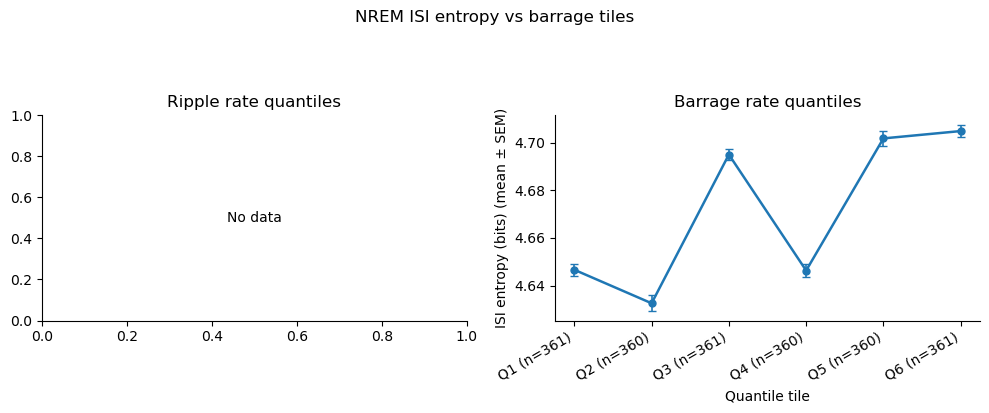

In [98]:
# Make 6-quantile tiles by ripple/barrage rate and plot
tiles_barr= aggregate_tiles(out_df, by="barrage",  value_col="isi_entropy", k=6)
tiles_barr = tiles_barr.reset_index().rename(columns={'index': 'tile_barrage'})


fig = plot_tiles_line(tiles_barr, tiles_barr, value_col="isi_entropy",
                      suptitle="NREM ISI entropy vs barrage tiles")
plt.show()

In [99]:
import pickle
save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\barr_ablate"
os.makedirs(save_dir, exist_ok=True)

# build filename and save
fname = f"{animal_name}_{day}.pkl"
save_path = os.path.join(save_dir, fname)

with open(save_path, "wb") as f:
    pickle.dump({"per_center": out_df,
                 "animal_name": animal_name,
                 "day": day}, f)

print(f"✅ Saved {save_path}")


✅ Saved D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\barr_ablate\NN16_day13.pkl
